In [13]:
%pip install huggingface_hub

Note: you may need to restart the kernel to use updated packages.


In [14]:
import re, csv, os, time, io, zipfile, urllib.request
from collections import Counter
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import pandas as pd
import matplotlib.pyplot as plt


In [15]:

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", device)

BASE_URL = "https://raw.githubusercontent.com/mhjabreel/CharCnn_Keras/master/data/ag_news_csv/"

def load_ag_news(split):
    path = f"ag_news_{split}.csv"
    if not os.path.exists(path):
        urllib.request.urlretrieve(BASE_URL + f"{split}.csv", path)
    data = []
    with open(path, encoding="utf-8") as f:
        for label, title, desc in csv.reader(f):
            text = (title + " " + desc).replace("\\", " ")
            data.append((int(label) - 1, text))
    return data

train_raw = load_ag_news("train")
test_raw = load_ag_news("test")
print(len(train_raw), "noticias de entrenamiento,", len(test_raw), "de test")

def tokenizer(text):
    return re.findall(r"\w+|[^\w\s]", text.lower())

counter = Counter()
for _, text in train_raw:
    counter.update(tokenizer(text))

itos = ["<pad>", "<unk>"] + [w for w, _ in counter.most_common()]
stoi = {w: i for i, w in enumerate(itos)}

class Vocab:
    def __init__(self, stoi): self.stoi = stoi
    def __len__(self): return len(self.stoi)
    def __getitem__(self, tok): return self.stoi.get(tok, self.stoi["<unk>"])
    def __call__(self, tokens): return [self[t] for t in tokens]
    def get_stoi(self): return self.stoi

vocab = Vocab(stoi)
print("Tamaño del vocabulario:", len(vocab))

text_pipeline = lambda x: vocab(tokenizer(x))

Dispositivo: cuda
120000 noticias de entrenamiento, 7600 de test
Tamaño del vocabulario: 65062


In [16]:
train_ds = [(label, text_pipeline(text)) for label, text in train_raw]
test_ds = [(label, text_pipeline(text)) for label, text in test_raw]

def collate_batch(batch):
    labels = torch.tensor([label for label, _ in batch], dtype=torch.long)
    texts = [torch.tensor(ids, dtype=torch.long) for _, ids in batch]
    padded = nn.utils.rnn.pad_sequence(texts, batch_first=True, padding_value=vocab["<pad>"])
    return labels, padded

train_dataloader = DataLoader(train_ds, batch_size=64, shuffle=True, collate_fn=collate_batch)
test_dataloader = DataLoader(test_ds, batch_size=64, shuffle=False, collate_fn=collate_batch)

In [17]:
from huggingface_hub import hf_hub_download

glove_zip = hf_hub_download(repo_id="stanfordnlp/glove", filename="glove.6B.zip")
print("Descargado en:", glove_zip)

with zipfile.ZipFile(glove_zip) as z:
    print(z.namelist())

Descargado en: C:\Users\Carlota\.cache\huggingface\hub\models--stanfordnlp--glove\snapshots\1db2080b2d94def6e5b0386a523102f9d8849e9d\glove.6B.zip
['glove.6B.100d.txt', 'glove.6B.200d.txt', 'glove.6B.300d.txt', 'glove.6B.50d.txt']


In [18]:
def build_embedding_matrix(zip_path, dim):
    filename = f"glove.6B.{dim}d.txt"
    stoi = vocab.get_stoi()
    found = {}

    with zipfile.ZipFile(zip_path) as z, z.open(filename) as f:
        for line in io.TextIOWrapper(f, encoding="utf-8"):
            parts = line.rstrip().split(" ")
            word = parts[0]
            if word in stoi:
                found[word] = np.asarray(parts[1:], dtype=np.float32)

    rng = np.random.default_rng(0)
    matrix = rng.normal(0, 0.1, (len(vocab), dim)).astype(np.float32)
    
    for word, vec in found.items():
        matrix[stoi[word]] = vec

    matrix[stoi["<pad>"]] = 0.0

    coverage = len(found) / len(vocab)
    print(f"GloVe {dim}d: {len(found)} de {len(vocab)} palabras encontradas ({coverage:.1%})")
    return torch.from_numpy(matrix)

In [19]:
class LSTMTextClassificationModel(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, num_class,
                 pretrained_embeddings=None, freeze_embeddings=False):
        super().__init__()
        if pretrained_embeddings is not None:
            self.embedding = nn.Embedding.from_pretrained(
                pretrained_embeddings, freeze=freeze_embeddings,
                padding_idx=vocab["<pad>"]
            )
        else:
            self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, num_class)

    def forward(self, text):
        lengths = (text != vocab["<pad>"]).sum(dim=1)

        embedded = self.embedding(text)
        lstm_out, _ = self.lstm(embedded)

        batch_indices = torch.arange(
            text.size(0), device=text.device
        )
        last_output = lstm_out[batch_indices, lengths - 1, :]

        return self.fc(last_output)

In [20]:
EPOCHS = 10
LR = 5
HIDDEN_DIM = 64
NUM_CLASS = 4

def train_epoch(model, dataloader, criterion, optimizer):
    model.train()
    total_acc, total_count = 0, 0
    for label, text in dataloader:
        label, text = label.to(device), text.to(device)
        optimizer.zero_grad()
        pred = model(text)
        loss = criterion(pred, label)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 0.1)
        optimizer.step()
        total_acc += (pred.argmax(1) == label).sum().item()
        total_count += label.size(0)
    return total_acc / total_count

def evaluate(model, dataloader):
    model.eval()
    total_acc, total_count = 0, 0
    with torch.no_grad():
        for label, text in dataloader:
            label, text = label.to(device), text.to(device)
            pred = model(text)
            total_acc += (pred.argmax(1) == label).sum().item()
            total_count += label.size(0)
    return total_acc / total_count

def run_experiment(name, embed_dim, pretrained=None, freeze=False):
    torch.manual_seed(0)
    model = LSTMTextClassificationModel(len(vocab), embed_dim, HIDDEN_DIM, NUM_CLASS,
                                        pretrained, freeze).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=LR)

    history = []
    print(f"\n=== {name} ===")
    for epoch in range(1, EPOCHS + 1):
        t0 = time.time()
        acc_train = train_epoch(model, train_dataloader, criterion, optimizer)
        acc_test = evaluate(model, test_dataloader)
        history.append(acc_test)
        print(f"Época {epoch:2d} | train {acc_train:.3f} | test {acc_test:.3f} | {time.time()-t0:.1f}s")
    return history

In [21]:
results = {}

results["Aleatorio 32d"] = run_experiment("Aleatorio 32d", 32)

for dim in [50, 100, 200, 300]:
    emb = build_embedding_matrix(glove_zip, dim)
    results[f"GloVe {dim}d"] = run_experiment(f"GloVe {dim}d", dim, emb, freeze=False)


=== Aleatorio 32d ===
Época  1 | train 0.633 | test 0.790 | 12.1s
Época  2 | train 0.827 | test 0.840 | 11.8s
Época  3 | train 0.865 | test 0.867 | 12.2s
Época  4 | train 0.884 | test 0.872 | 12.8s
Época  5 | train 0.900 | test 0.883 | 12.4s
Época  6 | train 0.911 | test 0.882 | 12.2s
Época  7 | train 0.919 | test 0.887 | 12.6s
Época  8 | train 0.928 | test 0.888 | 13.3s
Época  9 | train 0.935 | test 0.886 | 12.5s
Época 10 | train 0.941 | test 0.889 | 12.6s
GloVe 50d: 57064 de 65062 palabras encontradas (87.7%)

=== GloVe 50d ===
Época  1 | train 0.870 | test 0.904 | 12.8s
Época  2 | train 0.914 | test 0.913 | 12.6s
Época  3 | train 0.926 | test 0.916 | 11.8s
Época  4 | train 0.932 | test 0.920 | 12.3s
Época  5 | train 0.939 | test 0.921 | 12.2s
Época  6 | train 0.945 | test 0.921 | 12.3s
Época  7 | train 0.950 | test 0.923 | 12.9s
Época  8 | train 0.955 | test 0.922 | 12.4s
Época  9 | train 0.961 | test 0.921 | 12.8s
Época 10 | train 0.965 | test 0.916 | 12.3s
GloVe 100d: 57064 de 65

In [22]:
emb100 = build_embedding_matrix(glove_zip, 100)
results["GloVe 100d (congelado)"] = run_experiment("GloVe 100d congelado", 100, emb100, freeze=True)

GloVe 100d: 57064 de 65062 palabras encontradas (87.7%)

=== GloVe 100d congelado ===
Época  1 | train 0.872 | test 0.902 | 13.2s
Época  2 | train 0.911 | test 0.911 | 11.2s
Época  3 | train 0.917 | test 0.915 | 11.9s
Época  4 | train 0.923 | test 0.913 | 10.8s
Época  5 | train 0.928 | test 0.917 | 11.2s
Época  6 | train 0.932 | test 0.919 | 11.8s
Época  7 | train 0.936 | test 0.920 | 11.1s
Época  8 | train 0.939 | test 0.917 | 11.4s
Época  9 | train 0.942 | test 0.919 | 11.0s
Época 10 | train 0.945 | test 0.919 | 11.1s


,Modelo,Exactitud final en test (%),Primera época >80%
0,Aleatorio 32d,88.91,2
1,GloVe 50d,91.55,1
2,GloVe 100d,91.55,1
3,GloVe 200d,92.32,1
4,GloVe 300d,91.89,1
5,GloVe 100d (congelado),91.89,1


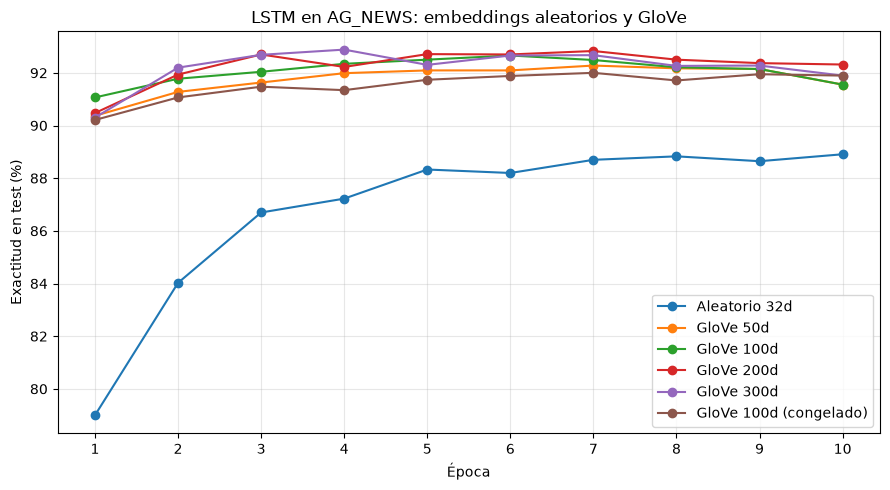

In [23]:
summary = pd.DataFrame({
    "Modelo": list(results.keys()),
    "Exactitud final en test (%)": [
        h[-1] * 100 for h in results.values()
    ],
    "Primera época >80%": [
        next(
            (i + 1 for i, acc in enumerate(h) if acc > 0.8),
            None
        )
        for h in results.values()
    ],
})

summary["Primera época >80%"] = (
    summary["Primera época >80%"].astype("Int64")
)

display(
    summary.style.format(
        {"Exactitud final en test (%)": "{:.2f}"},
        na_rep="—"
    )
)

plt.figure(figsize=(9, 5))

for name, history in results.items():
    plt.plot(
        range(1, len(history) + 1),
        [acc * 100 for acc in history],
        marker="o",
        label=name
    )

plt.xlabel("Época")
plt.ylabel("Exactitud en test (%)")
plt.title("LSTM en AG_NEWS: embeddings aleatorios y GloVe")
plt.xticks(range(1, EPOCHS + 1))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()